In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv('/content/gold_price_cleaned.csv')
print(df.head())

    Price/gram  Price/oz        Date   Returns  Volatility_30d
0  2443.529228   76002.0  2015-02-11 -0.011420        0.186554
1  2434.623442   75725.0  2015-02-12 -0.003645        0.185995
2  2452.370713   76277.0  2015-02-13  0.007290        0.181980
3  2462.337478   76587.0  2015-02-16  0.004064        0.176656
4  2415.911645   75143.0  2015-02-17 -0.018854        0.182205


In [ ]:
df = df.drop(columns=['Price/oz'])
display(df.head())

,Price/gram,Date,Returns,Volatility_30d
0,2443.529228,2015-02-11,-0.011420,0.186554
1,2434.623442,2015-02-12,-0.003645,0.185995
2,2452.370713,2015-02-13,0.007290,0.181980
3,2462.337478,2015-02-16,0.004064,0.176656
4,2415.911645,2015-02-17,-0.018854,0.182205


### Linear Regression Modeling
We will train a Linear Regression model to predict `Price/gram` using features like `Returns` and `Volatility_30d`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

df_clean = df.dropna(subset=['Price/gram', 'Returns', 'Volatility_30d'])

X = df_clean[['Returns', 'Volatility_30d']]
y = df_clean['Price/gram']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Model Coefficients: {model.coef_}")
print(f"Model Intercept: {model.intercept_:.4f}")

Mean Squared Error (MSE): 5463686.1822
R-squared (R2) Score: 0.2486
Model Coefficients: [ 9538.76421345 24688.43543988]
Model Intercept: 1268.0490


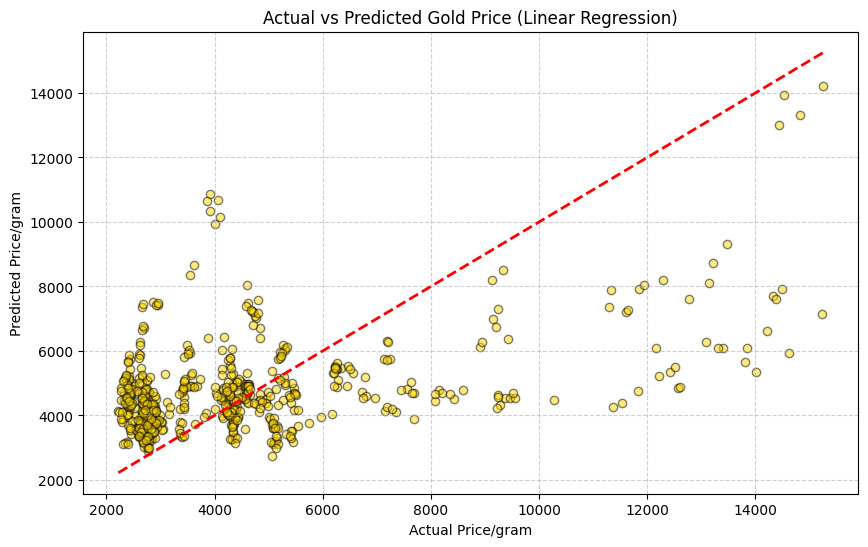

In [ ]:

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='gold', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price/gram')
plt.ylabel('Predicted Price/gram')
plt.title('Actual vs Predicted Gold Price (Linear Regression)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Training a Time-Based Trend Model for Future Price Prediction
To project gold prices into the future, we will convert the `Date` column into numerical days from the start of the dataset and fit a Linear Regression model.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

df['Date'] = pd.to_datetime(df['Date'])

# Calculate days from the start date to use as a numerical feature
start_date = df['Date'].min()
df['Days_Since_Start'] = (df['Date'] - start_date).dt.days

trend_model = LinearRegression()
X_trend = df[['Days_Since_Start']]
y_trend = df['Price/gram']
trend_model.fit(X_trend, y_trend)

print(f"Trend Model Trained!")
print(f"Intercept (Price at start): {trend_model.intercept_:.4f}")
print(f"Slope (Daily price increase): {trend_model.coef_[0]:.4f}")

Trend Model Trained!
Intercept (Price at start): 663.3127
Slope (Daily price increase): 1.9856


### Investment Projection Simulation Function
Now we will build a function that accepts `monthly_investment` and `target_years`. It calculates the monthly accumulation of gold using predicted future prices month-by-month.

In [ ]:
def project_investment(monthly_investment, target_years):

    latest_date = df['Date'].max()
    latest_days = (latest_date - start_date).days

    total_grams_accumulated = 0
    total_invested = 0

    # Project month by month
    total_months = int(target_years * 12)

    for month in range(1, total_months + 1):

        future_days = latest_days + (month * 30)

        input_df = pd.DataFrame({'Days_Since_Start': [future_days]})


        predicted_price = trend_model.predict(input_df)[0]


        predicted_price = max(predicted_price, 100.0)


        grams_bought = monthly_investment / predicted_price

        total_grams_accumulated += grams_bought
        total_invested += monthly_investment


    final_future_days = latest_days + (total_months * 30)
    final_input_df = pd.DataFrame({'Days_Since_Start': [final_future_days]})
    final_predicted_price = trend_model.predict(final_input_df)[0]

    projected_value = total_grams_accumulated * final_predicted_price

    return {
        "total_invested": total_invested,
        "total_grams_accumulated": total_grams_accumulated,
        "final_predicted_price_per_gram": final_predicted_price,
        "projected_value": projected_value,
        "net_gain_loss": projected_value - total_invested
    }

# Demo run with 15k monthly investment for 10 years
demo_results = project_investment(monthly_investment=15000, target_years=10)

print(f"--- Projection over 10 Years with 15,000/month ---")
print(f"Total Amount Invested: {demo_results['total_invested']:,} units")
print(f"Total Gold Grams Accumulated: {demo_results['total_grams_accumulated']:.2f} grams")
print(f"Projected Gold Price at Year 10: {demo_results['final_predicted_price_per_gram']:.2f} per gram")
print(f"Projected Portfolio Value: {demo_results['projected_value']:,.2f} Rs")
print(f"Projected Net Profit: {demo_results['net_gain_loss']:,.2f} Rs")


--- Projection over 10 Years with 15,000/month ---
Total Amount Invested: 1,800,000 units
Total Gold Grams Accumulated: 147.86 grams
Projected Gold Price at Year 10: 16065.55 per gram
Projected Portfolio Value: 2,375,484.33 Rs
Projected Net Profit: 575,484.33 Rs


In [ ]:
# Calculate projection for 10k monthly for 3 years
custom_results = project_investment(monthly_investment=10000, target_years=3)

target_goal = 600000
achieved = custom_results['projected_value'] >= target_goal

print(f"--- Projection over 3 Years with 10,000/month ---")
print(f"Total Amount Invested: {custom_results['total_invested']:,} units")
print(f"Total Gold Grams Accumulated: {custom_results['total_grams_accumulated']:.2f} grams")
print(f"Projected Gold Price at Year 3: {custom_results['final_predicted_price_per_gram']:.2f} per gram")
print(f"Projected Portfolio Value: {custom_results['projected_value']:,.2f} units")
print(f"Projected Net Profit: {custom_results['net_gain_loss']:,.2f} units")
print(f"Target Goal of 6 Lakhs Reached?: {'Yes! 🎉' if achieved else 'No ❌'}")

--- Projection over 3 Years with 10,000/month ---
Total Amount Invested: 360,000 units
Total Gold Grams Accumulated: 36.07 grams
Projected Gold Price at Year 3: 11061.86 per gram
Projected Portfolio Value: 398,981.48 units
Projected Net Profit: 38,981.48 units
Target Goal of 6 Lakhs Reached?: No ❌
